# 03 · Possession chains and EPV

What a possession is worth, and what makes it worth that.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DERIVED_DIR, PROCESSED_DIR, PALETTE
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "grid.color": PALETTE["grid"],
    "axes.edgecolor": PALETTE["line"], "text.color": PALETTE["text"],
    "axes.labelcolor": PALETTE["text_secondary"], "xtick.color": PALETTE["muted"],
    "ytick.color": PALETTE["muted"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 140, "display.max_columns", 40)


In [2]:
poss = pd.read_parquet(DERIVED_DIR / "possessions.parquet")
tp = pd.read_parquet(DERIVED_DIR / "team_possessions.parquet")
print(f"{len(poss):,} player possessions in {len(tp):,} chains")
print(f"EPV populated on {poss.possession_epv_total.notna().mean():.0%} of possessions")
tp[["team", "duration_s", "n_player_possessions", "n_passes", "territory_gain_m",
    "epv_total", "lead_to_shot"]].describe().round(3)

18,792 player possessions in 7,523 chains
EPV populated on 76% of possessions


,duration_s,n_player_possessions,n_passes,territory_gain_m,epv_total
count,7523.000,7523.000,7523.000,7501.000,5743.000
mean,6.072,2.498,2.171,5.542,0.004
std,7.244,2.187,2.195,17.056,0.024
min,0.000,1.000,0.000,-91.090,-0.368
25%,1.400,1.000,1.000,-1.228,-0.001
50%,3.800,2.000,1.000,1.201,0.001
75%,8.300,3.000,3.000,12.025,0.007
max,187.100,22.000,22.000,95.903,0.419


## Phases of play are not equally valuable

In [3]:
by = tp.groupby("team_in_possession_phase_type").agg(
    n=("epv_total", "size"), share=("epv_total", lambda s: len(s) / len(tp)),
    duration_s=("duration_s", "mean"), territory_m=("territory_gain_m", "mean"),
    shot_rate=("lead_to_shot", "mean"), epv=("epv_total", "mean")).sort_values("epv", ascending=False)
by.round(4)

,n,share,duration_s,territory_m,shot_rate,epv
team_in_possession_phase_type,,,,,,
transition,187,0.0249,10.4193,48.1840,0.2299,0.0309
quick_break,105,0.0140,7.3029,22.5791,0.4476,0.0202
finish,1507,0.2003,8.3721,6.5683,0.1958,0.0046
build_up,1073,0.1426,6.7284,-0.1462,0.0075,0.0045
chaotic,1632,0.2169,1.5823,2.3770,0.0018,0.0029
direct,496,0.0659,2.2103,3.6061,0.0141,0.0027
set_play,245,0.0326,4.6776,7.7037,0.4122,0.0023
create,2278,0.3028,8.0360,5.6945,0.0413,0.0023


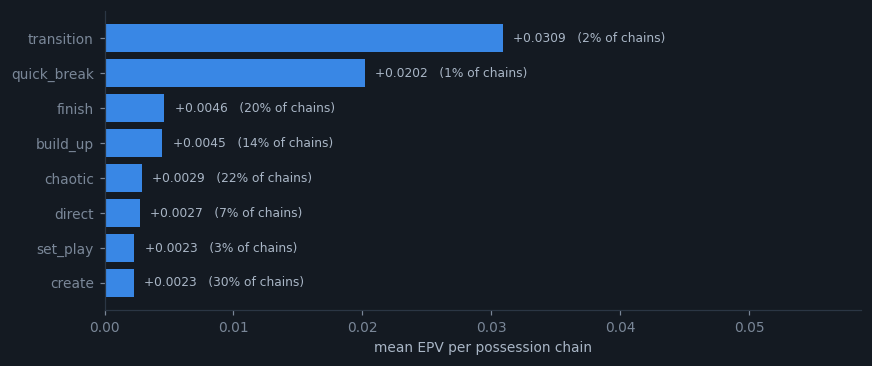

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
b = by.sort_values("epv")
ax.barh(b.index, b.epv, color=PALETTE["accent"])
for i, (v, s) in enumerate(zip(b.epv, b.share)):
    ax.text(v + 0.0008, i, f"{v:+.4f}   ({s:.0%} of chains)", va="center", fontsize=8,
            color=PALETTE["text_secondary"])
ax.set_xlabel("mean EPV per possession chain"); ax.set_xlim(right=b.epv.max() * 1.9)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()

Transitions and quick breaks are worth several times a build-up possession and make up under 4% of chains.

## Pressure

In [5]:
order = ["no_pressure", "low_pressure", "medium_pressure", "high_pressure",
         "very_high_pressure"]
p = poss[poss.end_type == "pass"]
g = p.assign(ok=p.pass_outcome == "successful").groupby("overall_pressure_start").agg(
    n=("ok", "size"), completion=("ok", "mean"), pass_epv=("pass_epv_total", "mean"),
    nearest_opponent_m=("fil_nearest_opponent_m", "mean")).reindex(order)
g.round(4)

,n,completion,pass_epv,nearest_opponent_m
overall_pressure_start,,,,
no_pressure,3779,0.9360,0.0020,11.8252
low_pressure,2617,0.8938,0.0024,7.1272
medium_pressure,3002,0.8241,0.0028,4.9630
high_pressure,1839,0.7232,0.0009,2.8054
very_high_pressure,224,0.6429,-0.0008,1.3040


`nearest_opponent_m` is computed here from tracking and never enters
SkillCorner's pressure model, so the monotone 11.8 m -> 1.3 m gradient is an
independent confirmation that the bands mean what they say.

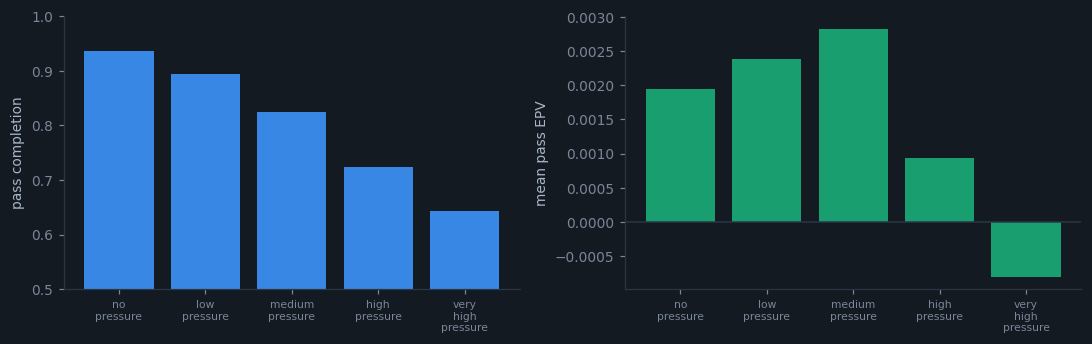

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(range(5), g.completion, color=PALETTE["accent"])
ax[0].set_xticks(range(5)); ax[0].set_xticklabels([o.replace("_", "\n") for o in order], fontsize=7)
ax[0].set_ylabel("pass completion"); ax[0].set_ylim(0.5, 1.0)
ax[1].bar(range(5), g.pass_epv, color=PALETTE["good"])
ax[1].set_xticks(range(5)); ax[1].set_xticklabels([o.replace("_", "\n") for o in order], fontsize=7)
ax[1].set_ylabel("mean pass EPV"); ax[1].axhline(0, color=PALETTE["line"], lw=1)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

Completion falls monotonically. Value added does not: it peaks at *medium* pressure and only turns negative at very high pressure.